In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    f1_score, accuracy_score, roc_auc_score, brier_score_loss, confusion_matrix
)
from sklearn.calibration import calibration_curve
from sklearn.decomposition import PCA
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Load the dataset
from pathlib import Path

_candidates = [
    Path("data/processed/ECOLI_W_API.csv"),
    Path("../../data/processed/ECOLI_W_API.csv"),
]
_path = next((p for p in _candidates if p.exists()), None)
if _path is None:
    raise FileNotFoundError(
        "Could not find data/processed/ECOLI_W_API.csv. "
        "Run this notebook from the repo root or from src/modeling."
    )
df = pd.read_csv(_path)

# Create binary target variable: 1 if unsafe (>=100), 0 if safe (<100)
df['SAFETY'] = (df['RESULT..MPN.100ML.'] >= 100).astype(int)

# Normalize column names (remove spaces)
df.columns = df.columns.str.replace(' ', '')

# Define initial feature set
features = [
    'TEMPERATURE', 'HUMIDITY', 'PRECIPITATION', 'DEW', 'WINDSPEED', 'WINDGUST',
    'WINDDIR', 'PRESSURE', 'CLOUDCOVER', 'SOLARRADIATION', 'SOLARENERGY', 'UVINDEX'
]

# Fill missing values
df[features] = df[features].fillna(df[features].mean())

# Feature selection based on correlation
correlations = df[features + ['SAFETY']].corr()['SAFETY'].drop('SAFETY').sort_values(ascending=False)
selected_features = correlations[correlations.abs() > 0.05].index.tolist()

# Prepare dataset
X = df[selected_features]
y = df['SAFETY']
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
# ECE definition
def ece_score(y_true, y_prob, n_bins=10):
    prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=n_bins)
    return np.average(np.abs(np.array(prob_pred) - np.array(prob_true)))

# Evaluation function to return metrics
def evaluate_model(model, X_test, y_test):
    y_prob = model.predict_proba(X_test)[:, 1]
    y_pred = model.predict(X_test)

    return {
        'F1': f1_score(y_test, y_pred),
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_prob),
        'Brier': brier_score_loss(y_test, y_prob),
        'ECE': ece_score(y_test, y_prob)
    }

# Store all results
results = {
    'Model': [],
    'F1': [],
    'Accuracy': [],
    'AUC': [],
    'Brier': [],
    'ECE': []
}

# Repeat experiment 20 times
for seed in range(20):
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y, test_size=0.5, random_state=seed
    )

    # ---- Tune k for KNN ----
    knn_params = {'n_neighbors': list(range(1, 21))}
    grid_knn = GridSearchCV(KNeighborsClassifier(), knn_params, scoring='f1', cv=5)
    grid_knn.fit(X_train, y_train)
    best_knn = grid_knn.best_estimator_

    # ---- Train XGBoost ----
    xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
    xgb.fit(X_train, y_train)

    # ---- Train Logistic Regression ----
    logreg = LogisticRegression(max_iter=1000)
    logreg.fit(X_train, y_train)

    # ---- Evaluate all models ----
    for model_name, model in [('KNN', best_knn), ('Logistic Regression', logreg), ('XGBoost', xgb)]:
        metrics = evaluate_model(model, X_test, y_test)
        results['Model'].append(model_name)
        for metric_name, value in metrics.items():
            results[metric_name].append(value)

# Convert to DataFrame
results_df = pd.DataFrame(results)
results_df

,Model,F1,Accuracy,AUC,Brier,ECE
0,KNN,0.639564,0.620564,0.655217,0.271167,0.198863
1,Logistic Regression,0.596491,0.567850,0.583338,0.246188,0.063289
2,XGBoost,0.634000,0.617954,0.680564,0.254602,0.159543
3,KNN,0.643666,0.638831,0.662945,0.265716,0.182973
4,Logistic Regression,0.609814,0.572547,0.595566,0.243892,0.044174
5,XGBoost,0.657201,0.647182,0.699882,0.241903,0.129489
6,KNN,0.633874,0.623173,0.649615,0.275922,0.200830
7,Logistic Regression,0.611394,0.562109,0.596538,0.244171,0.097354
8,XGBoost,0.650155,0.646138,0.701447,0.241746,0.128774
9,KNN,0.640569,0.631002,0.666214,0.238460,0.116542


**VISUALIZATIONS**

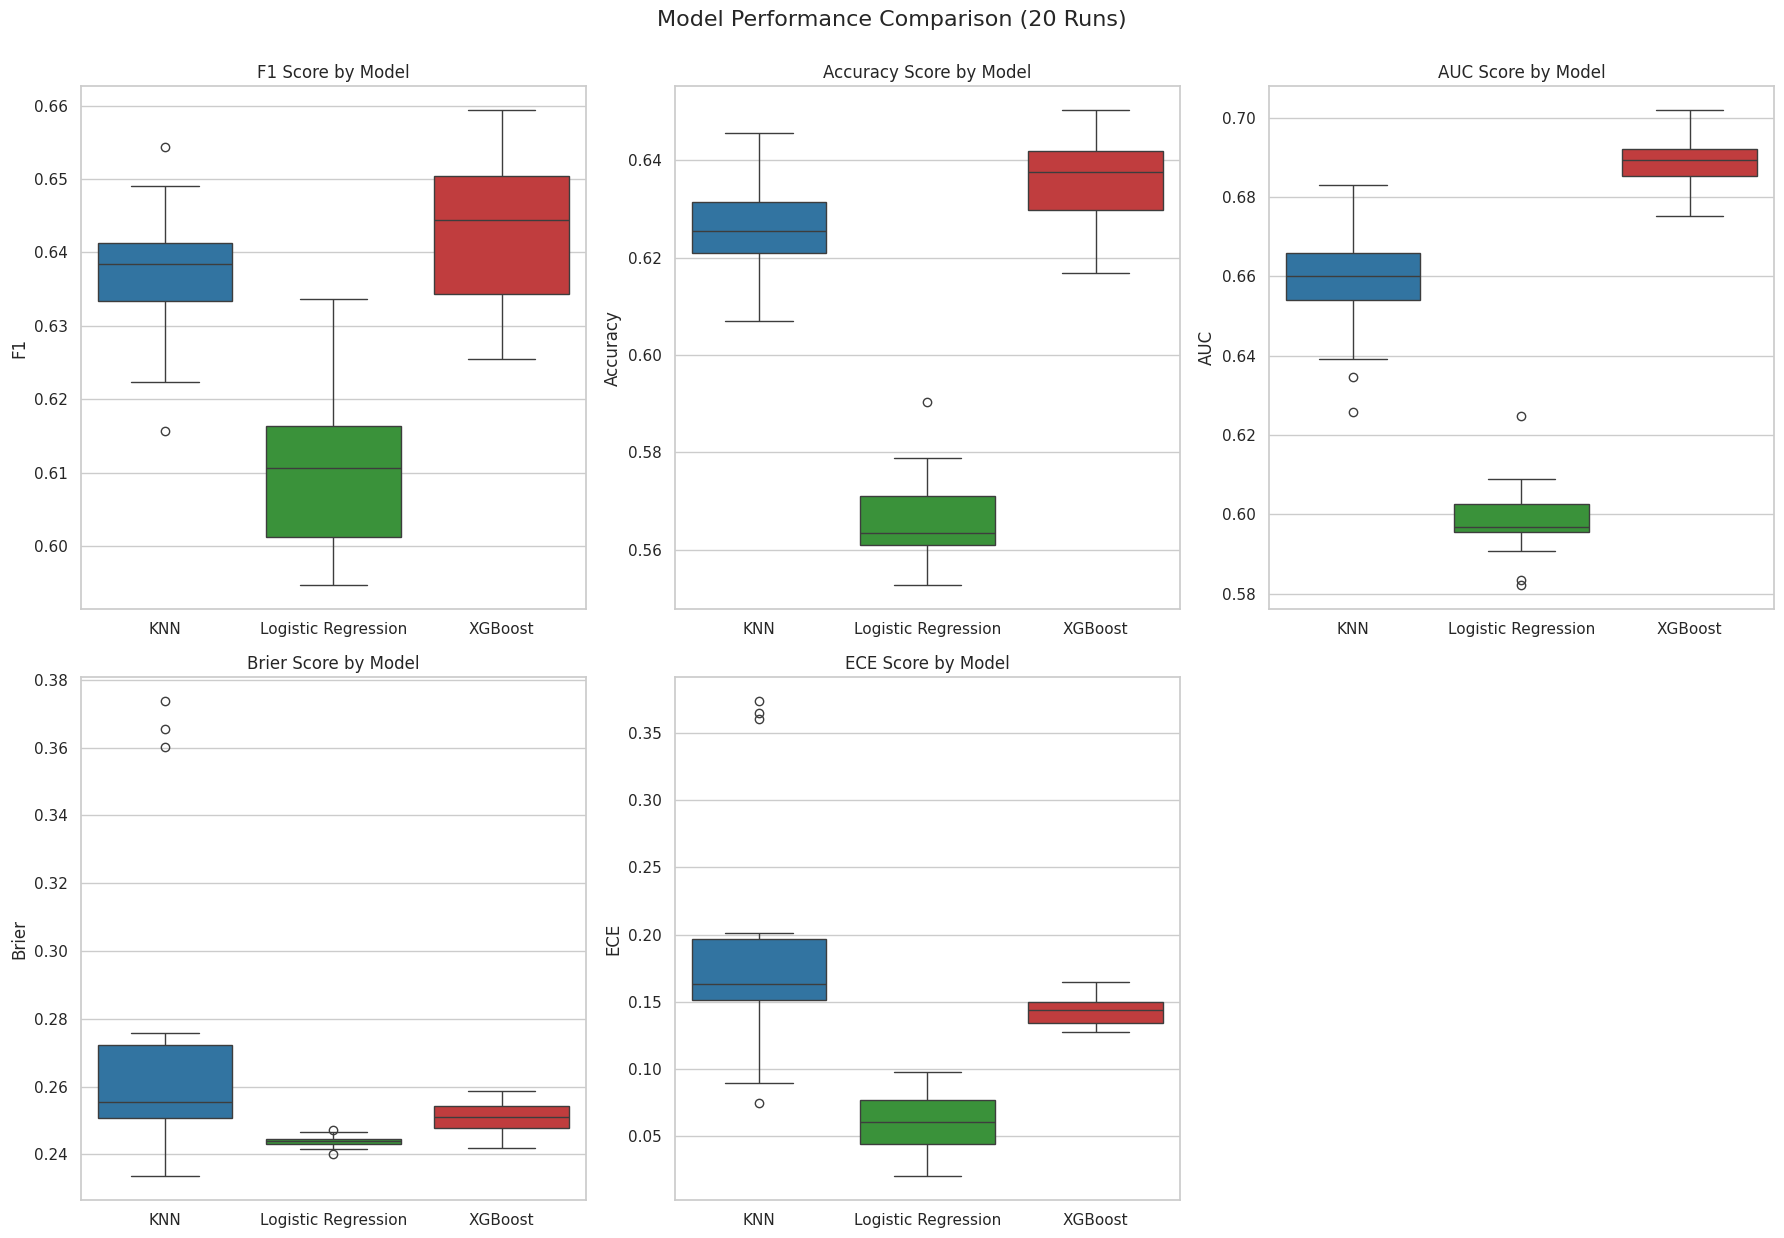

In [ ]:
# Set the plotting style
sns.set(style='whitegrid')
plt.figure(figsize=(18, 12))

metrics = ['F1', 'Accuracy', 'AUC', 'Brier', 'ECE']

# Define a color palette for consistency across plots
model_palette = {
    'KNN': '#1f77b4',
    'Logistic Regression': '#2ca02c',
    'XGBoost': '#d62728'
}

# Create a subplot for each metric
for i, metric in enumerate(metrics, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x='Model', y=metric, data=results_df, palette=model_palette)
    plt.title(f'{metric} Score by Model')
    plt.ylabel(metric)
    plt.xlabel('')

plt.tight_layout()
plt.suptitle("Model Performance Comparison (20 Runs)", fontsize=16, y=1.03)
plt.show()

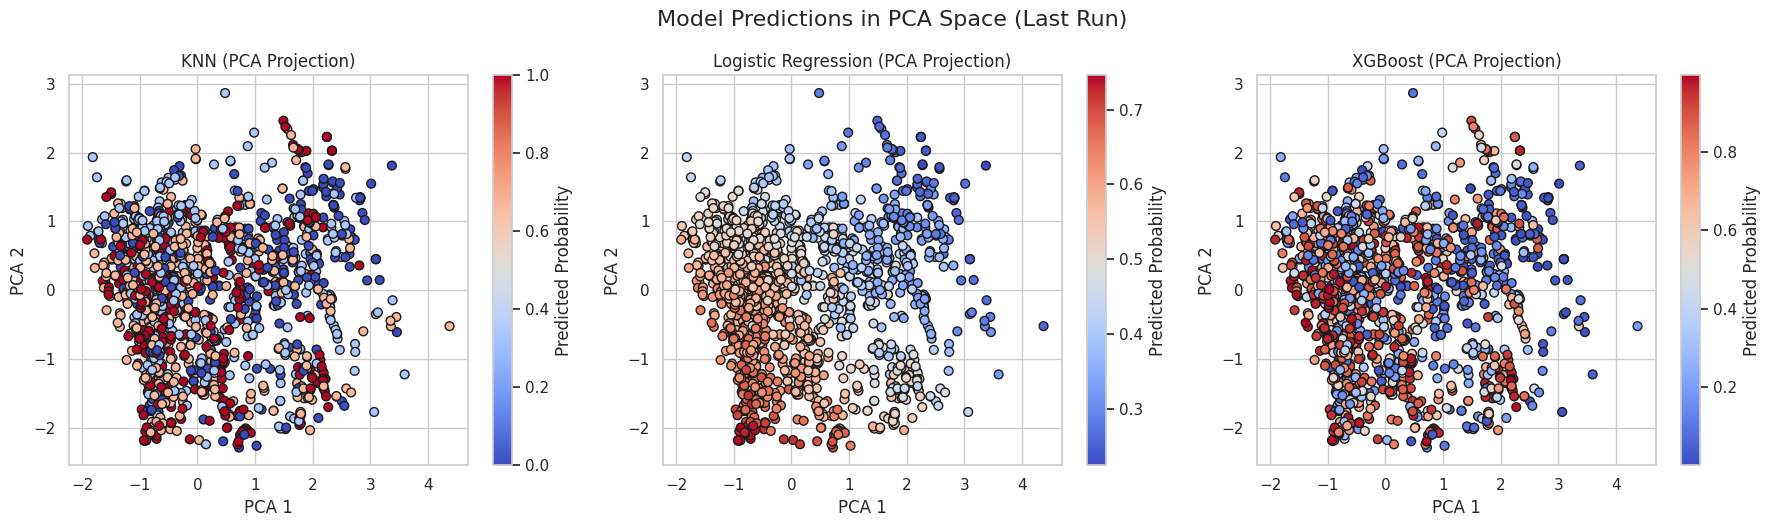

In [ ]:
# First PCA plot: Probability of being classified as safe or unsafe
pca = PCA(n_components=2)
X_test_pca = pca.fit_transform(X_test)

# Plot settings
plt.figure(figsize=(18, 5))
models_to_plot = {
    'KNN': best_knn,
    'Logistic Regression': logreg,
    'XGBoost': xgb
}

for i, (model_name, model) in enumerate(models_to_plot.items(), 1):
    y_prob = model.predict_proba(X_test)[:, 1]

    plt.subplot(1, 3, i)
    scatter = plt.scatter(
        X_test_pca[:, 0], X_test_pca[:, 1],
        c=y_prob, cmap='coolwarm', edgecolor='k', s=40
    )
    plt.title(f'{model_name} (PCA Projection)')
    plt.xlabel('PCA 1')
    plt.ylabel('PCA 2')
    plt.colorbar(scatter, label='Predicted Probability')

plt.tight_layout()
plt.suptitle("Model Predictions in PCA Space (Last Run)", fontsize=16, y=1.05)
plt.show()

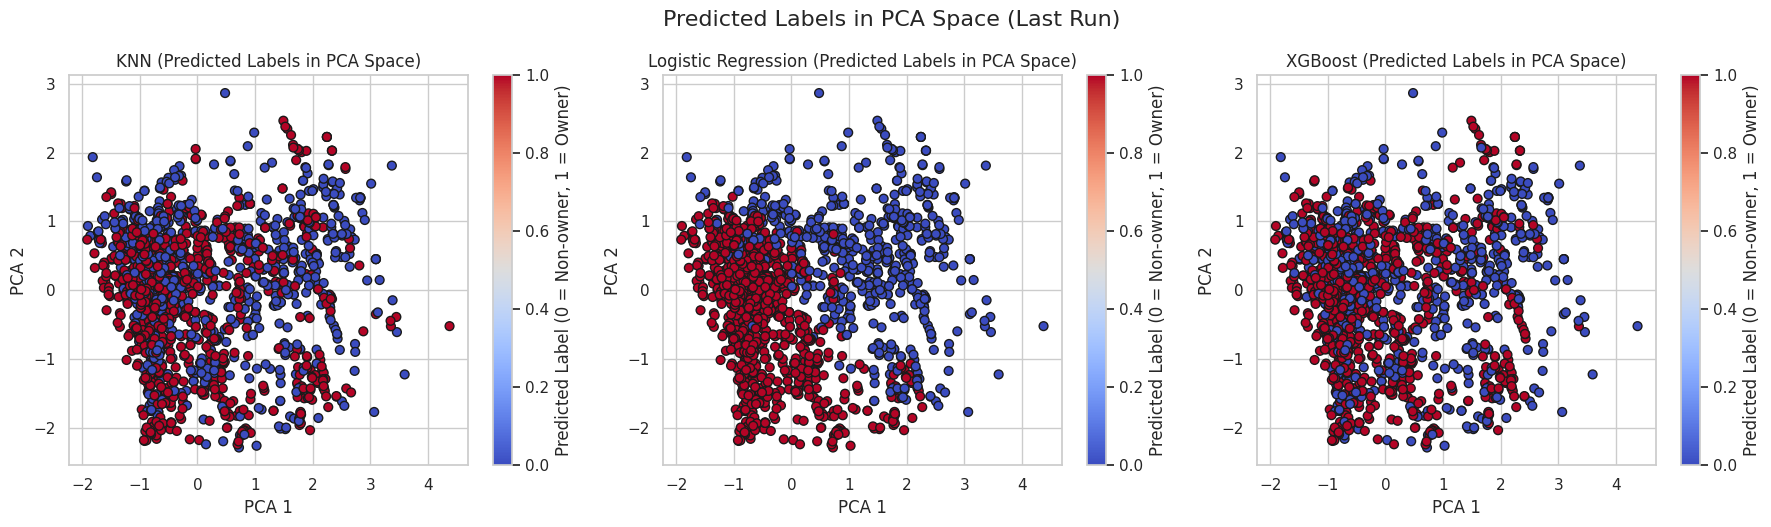

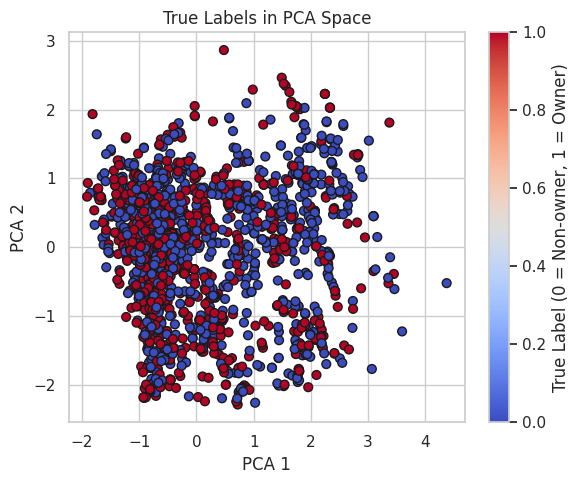

In [ ]:
# Second PCA plot: Predicted vs True Labels
plt.figure(figsize=(18, 5))

for i, (model_name, model) in enumerate(models_to_plot.items(), 1):
    y_pred = model.predict(X_test)

    plt.subplot(1, 3, i)
    scatter = plt.scatter(
        X_test_pca[:, 0], X_test_pca[:, 1],
        c=y_pred, cmap='coolwarm', edgecolor='k', s=40
    )
    plt.title(f'{model_name} (Predicted Labels in PCA Space)')
    plt.xlabel('PCA 1')
    plt.ylabel('PCA 2')
    plt.colorbar(scatter, label='Predicted Label (0 = Non-owner, 1 = Owner)')

plt.tight_layout()
plt.suptitle("Predicted Labels in PCA Space (Last Run)", fontsize=16, y=1.05)
plt.show()

# Plot true labels
plt.figure(figsize=(6, 5))
plt.scatter(
    X_test_pca[:, 0], X_test_pca[:, 1],
    c=y_test, cmap='coolwarm', edgecolor='k', s=40
)
plt.title("True Labels in PCA Space")
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.colorbar(label='True Label (0 = Non-owner, 1 = Owner)')
plt.tight_layout()
plt.show()

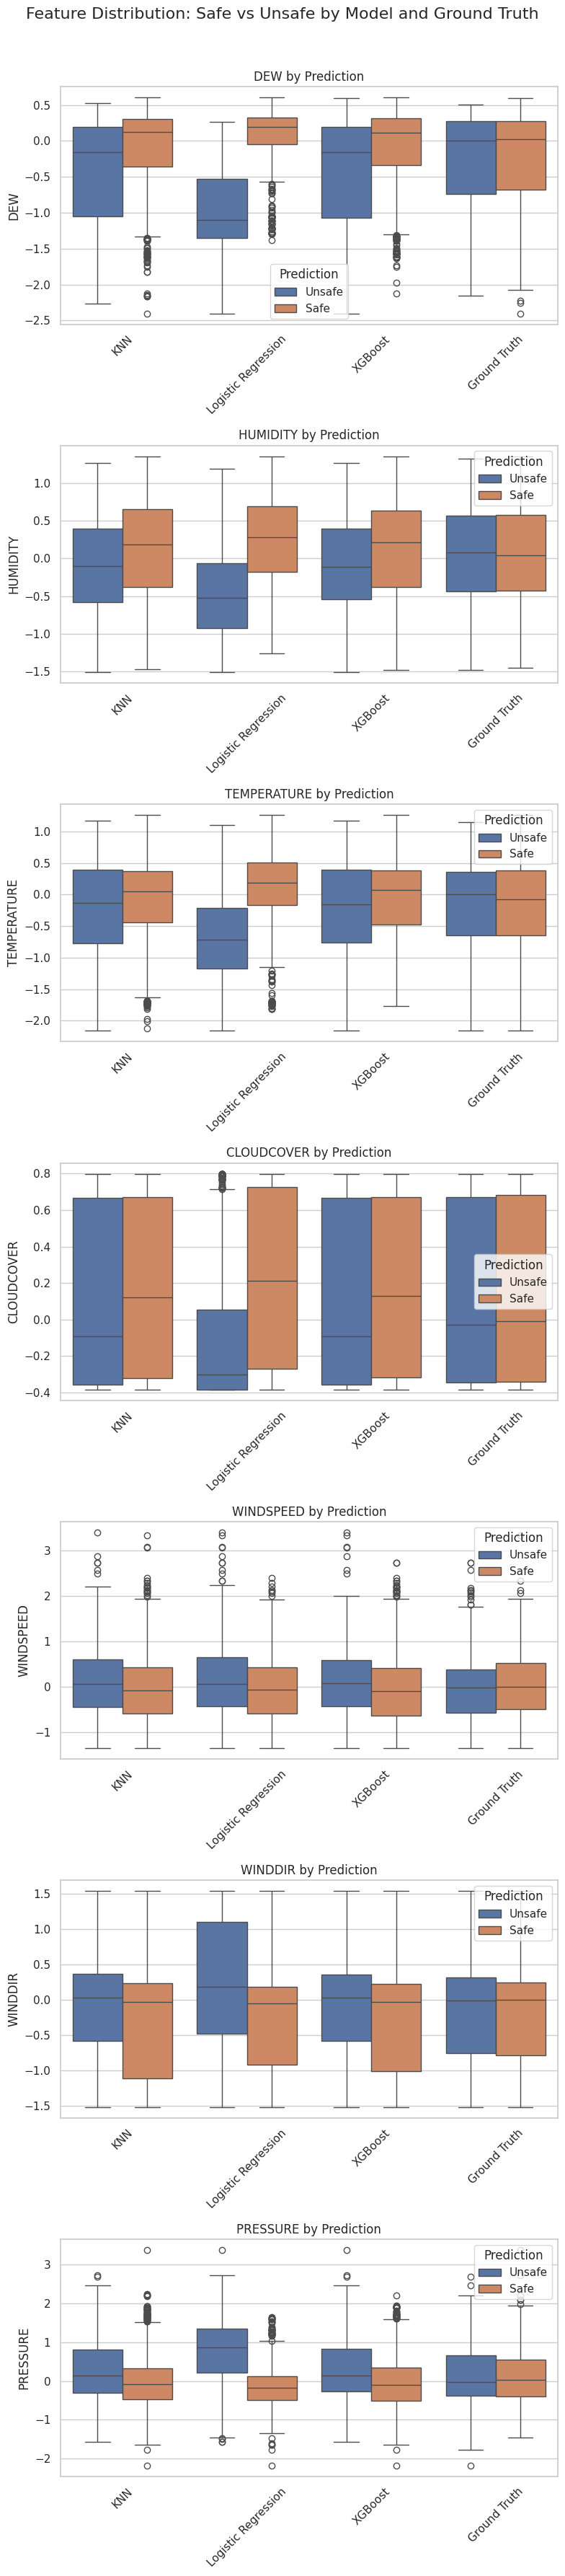

In [ ]:
# Build DataFrame with true and predicted labels
pca_df = pd.DataFrame(X_test, columns=selected_features)
pca_df['True_Label'] = y_test

# Add model predictions
for model_name, model in models_to_plot.items():
    pca_df[f'{model_name}_Pred'] = model.predict(X_test)

# Melt DataFrame into long format for plotting
long_data = []

for feature in selected_features:
    for model_name in models_to_plot.keys():
        for label in [0, 1]:
            values = pca_df[pca_df[f'{model_name}_Pred'] == label][feature]
            long_data.extend([
                {'Feature': feature, 'Value': v, 'Model': model_name, 'Prediction': 'Safe' if label == 1 else 'Unsafe'}
                for v in values
            ])

    # Also include ground truth
    for label in [0, 1]:
        values = pca_df[pca_df['True_Label'] == label][feature]
        long_data.extend([
            {'Feature': feature, 'Value': v, 'Model': 'Ground Truth', 'Prediction': 'Safe' if label == 1 else 'Unsafe'}
            for v in values
        ])

long_df = pd.DataFrame(long_data)

# Plot
plt.figure(figsize=(8, 5 * len(selected_features)))
for i, feature in enumerate(selected_features, 1):
    plt.subplot(len(selected_features), 1, i)
    sns.boxplot(data=long_df[long_df['Feature'] == feature], x='Model', y='Value', hue='Prediction')
    plt.title(f'{feature} by Prediction')
    plt.xticks(rotation=45)
    plt.ylabel(feature)
    plt.xlabel('')

plt.tight_layout()
plt.suptitle("Feature Distribution: Safe vs Unsafe by Model and Ground Truth", fontsize=16, y=1.02)
plt.show()

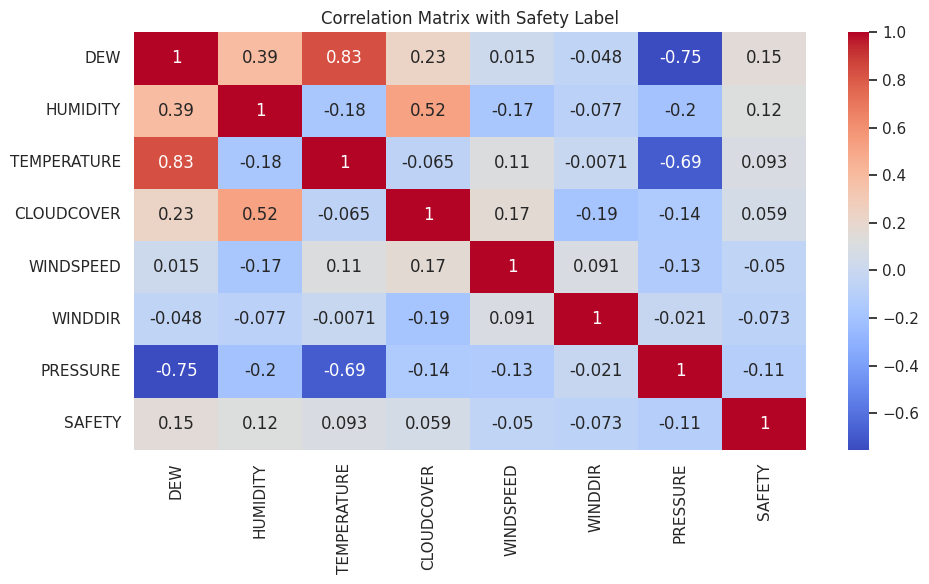

In [ ]:
# Correlation Heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(df[selected_features + ['SAFETY']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix with Safety Label')
plt.tight_layout()
plt.show()

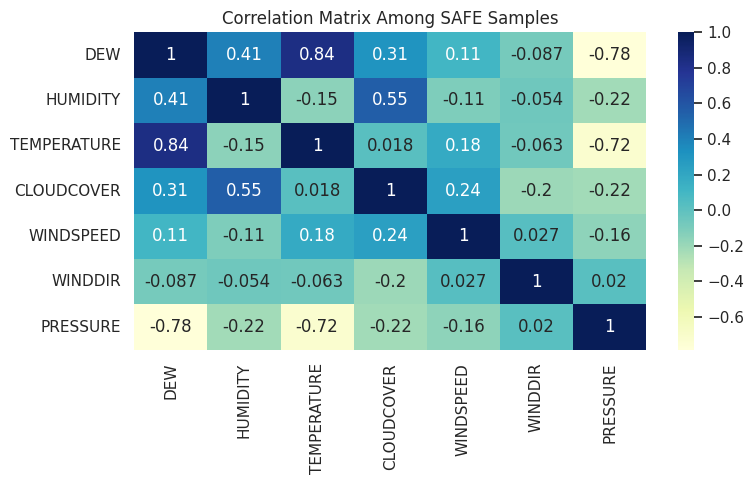

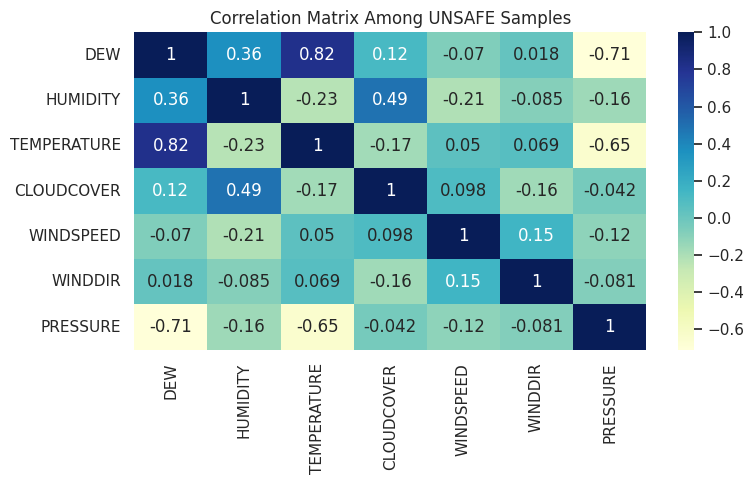

In [ ]:
# Correlation matrix for SAFE and UNSAFE samples
safe_df = df[df['SAFETY'] == 0]

plt.figure(figsize=(8, 5))
sns.heatmap(safe_df[selected_features].corr(), annot=True, cmap='YlGnBu')
plt.title('Correlation Matrix Among SAFE Samples')
plt.tight_layout()
plt.show()

safe_df = df[df['SAFETY'] == 1]

plt.figure(figsize=(8, 5))
sns.heatmap(safe_df[selected_features].corr(), annot=True, cmap='YlGnBu')
plt.title('Correlation Matrix Among UNSAFE Samples')
plt.tight_layout()
plt.show()